### 1. Import Libraries

In [62]:
import pandas as pd 
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
import re
warnings.filterwarnings('ignore')

### 2. Load Data

In [63]:
df_copy = pd.read_csv('dirty_cafe_sales.csv')
df = df_copy.copy()
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


### 3. Initial Data Inspection

In [64]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [65]:
df.describe()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


# 4. Issue Detection

### Dropping the duplicates

In [66]:
# Count total duplicate rows
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")


Number of duplicate rows: 0


In [67]:
df.drop_duplicates(inplace=True)


In [69]:
# Define the valid Transaction ID pattern: TXN_ + 7 digits
pattern = r'^TXN_\d{7}$'

# Identify rows that match the correct format
mask_valid_id = df['Transaction ID'].astype(str).str.match(pattern)

# Drop rows that do NOT match the pattern
df = df[mask_valid_id].copy()


## Replacing the values UNKNOWN and ERROR with NAN

In [71]:
# Replace 'UNKNOWN' and 'ERROR' with missing values across the dataframe
df.replace(['UNKNOWN', 'ERROR'], pd.NA, inplace=True)

# Quick confirmation of missing counts per column
for c in df.columns:
    print(f"{c}: {df[c].isna().sum()} missing")

Transaction ID: 0 missing
Item: 969 missing
Quantity: 479 missing
Price Per Unit: 533 missing
Total Spent: 502 missing
Payment Method: 3178 missing
Location: 3961 missing
Transaction Date: 460 missing


In [72]:
# Compute percentage of missing Transaction Date and rows not matching YYYY-MM-DD
total_rows = len(df)
missing_count = df[c].isna().sum()
missing_pct = missing_count / total_rows * 100

non_missing_mask = df[c].notna()
non_missing_count = non_missing_mask.sum()

# Count rows where the non-missing date does NOT match the exact pattern YYYY-MM-DD
invalid_mask = ~df.loc[non_missing_mask, c].astype(str).str.match(r'^\d{4}-\d{2}-\d{2}$')
invalid_count = invalid_mask.sum()
invalid_pct_of_total = invalid_count / total_rows * 100
invalid_pct_of_non_missing = invalid_count / non_missing_count * 100 if non_missing_count > 0 else np.nan

print(f"Total rows: {total_rows}")
print(f"Missing '{c}': {missing_count} rows ({missing_pct:.2f}%)")
print(f"Non-missing '{c}': {non_missing_count} rows")
print(f"Non-matching format: {invalid_count} rows "
    f"({invalid_pct_of_total:.2f}% of total, {invalid_pct_of_non_missing:.2f}% of non-missing)")

Total rows: 10000
Missing 'Transaction Date': 460 rows (4.60%)
Non-missing 'Transaction Date': 9540 rows
Non-matching format: 0 rows (0.00% of total, 0.00% of non-missing)


### Dropping the the rows with no transaction date as the percentage of the missing values is less than 5% in the columns "Transaction Date" so i choosing to drop it

In [73]:
import re

# Regex to match ONLY dates like 2023-07-19
pattern = r'^\d{4}-\d{2}-\d{2}$'

df = df[df['Transaction Date'].astype(str).str.match(pattern)]

# Convert 'Transaction Date' to datetime, coercing errors to NaT
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'], format='%Y-%m-%d', errors='coerce')


In [75]:
# Convert numeric columns to appropriate types
numeric_columns = ['Quantity', 'Price Per Unit', 'Total Spent']
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Filling the missing 
### Mapping each Item with its price 
### computing the missing values in the "Total Spent"
### Computing the quantity using the columns "Price Per Unit" and "Total Spent" 

In [76]:
# Create mapping: item to price
price_map = (
    df.dropna(subset=['Price Per Unit'])        
      .drop_duplicates(subset=['Item'])        
      .set_index('Item')['Price Per Unit']      
      .to_dict()                                
)
price_map

{'Coffee': 2.0,
 'Cake': 3.0,
 'Cookie': 1.0,
 'Salad': 5.0,
 'Smoothie': 4.0,
 <NA>: 3.0,
 'Sandwich': 4.0,
 nan: 3.0,
 'Juice': 3.0,
 'Tea': 1.5}

In [77]:
# Fill missing 'Price Per Unit' using the price_map
df['Price Per Unit'] = df['Price Per Unit'].fillna(
    df['Item'].map(price_map)
)
mask_missing_price = df['Price Per Unit'].isna() & df['Total Spent'].notna() & df['Quantity'].notna()

df.loc[mask_missing_price, 'Price Per Unit'] = (
    df.loc[mask_missing_price, 'Total Spent'] / df.loc[mask_missing_price, 'Quantity']
)


In [78]:
df['Price Per Unit'].isna().sum()

0

In [79]:
# Fill missing 'Total Spent' using Quantity * Price Per Unit
mask_missing_total = df['Total Spent'].isna() & df['Quantity'].notna() & df['Price Per Unit'].notna()

df.loc[mask_missing_total, 'Total Spent'] = (
    df.loc[mask_missing_total, 'Quantity'] * df.loc[mask_missing_total, 'Price Per Unit']
)


In [80]:
# Create reverse mapping: price to list of items
from collections import defaultdict

reverse_price_map = defaultdict(list)

for item, price in price_map.items():
    if price is not None:
        reverse_price_map[price].append(item)


In [81]:
# Helper function to pick the first item from a list
def pick_first(items_list):
    if isinstance(items_list, list) and len(items_list) > 0:
        return items_list[0]
    return None

mask_missing_item = df['Item'].isna() & df['Price Per Unit'].notna()

df.loc[mask_missing_item, 'Item'] = (
    df.loc[mask_missing_item, 'Price Per Unit']
    .map(reverse_price_map)
    .apply(pick_first)
)


In [82]:
# Fill missing 'Quantity' using Total Spent / Price Per Unit
mask_missing_qty = (
    df['Quantity'].isna() &
    df['Total Spent'].notna() &
    df['Price Per Unit'].notna() &
    (df['Price Per Unit'] != 0)
)

df.loc[mask_missing_qty, 'Quantity'] = (
    df.loc[mask_missing_qty, 'Total Spent'] / df.loc[mask_missing_qty, 'Price Per Unit']
)


In [83]:
# Final check of missing values
for c in df.columns:
    print(f"{c}: {df[c].isna().sum()} missing")

Transaction ID: 0 missing
Item: 0 missing
Quantity: 20 missing
Price Per Unit: 0 missing
Total Spent: 20 missing
Payment Method: 3015 missing
Location: 3779 missing
Transaction Date: 0 missing


In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9540 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    9540 non-null   object        
 1   Item              9540 non-null   object        
 2   Quantity          9520 non-null   float64       
 3   Price Per Unit    9540 non-null   float64       
 4   Total Spent       9520 non-null   float64       
 5   Payment Method    6525 non-null   object        
 6   Location          5761 non-null   object        
 7   Transaction Date  9540 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 670.8+ KB


In [85]:
item_mode = df['Item'].mode()[0]
df['Item'] = df['Item'].fillna(item_mode)

qty_mode = df['Quantity'].mode()[0]
df['Quantity'] = df['Quantity'].fillna(qty_mode)

df['Price Per Unit'] = df['Price Per Unit'].fillna(
    df['Item'].map(price_map)
)

df['Total Spent'] = df['Quantity'] * df['Price Per Unit']
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9540 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    9540 non-null   object        
 1   Item              9540 non-null   object        
 2   Quantity          9540 non-null   float64       
 3   Price Per Unit    9540 non-null   float64       
 4   Total Spent       9540 non-null   float64       
 5   Payment Method    6525 non-null   object        
 6   Location          5761 non-null   object        
 7   Transaction Date  9540 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 670.8+ KB


In [86]:
print(df['Location'].value_counts())
df['Payment Method'].value_counts()


Location
Takeaway    2889
In-store    2872
Name: count, dtype: int64


Payment Method
Digital Wallet    2197
Credit Card       2170
Cash              2158
Name: count, dtype: int64

In [87]:
# العلاقة بين Location و Payment Method
pd.crosstab(df['Location'], df['Payment Method'], margins=True, normalize='index')


Payment Method,Cash,Credit Card,Digital Wallet
Location,,,
In-store,0.339051,0.326438,0.334511
Takeaway,0.316608,0.323633,0.359759
All,0.327799,0.325031,0.347170


In [88]:
df[['Quantity','Price Per Unit','Total Spent']].corr()


,Quantity,Price Per Unit,Total Spent
Quantity,1.000000,0.007865,0.705969
Price Per Unit,0.007865,1.000000,0.645475
Total Spent,0.705969,0.645475,1.000000


### Outlier detection

Payment Method      Cash  Credit Card  Digital Wallet
Location                                             
In-store        9.181548     8.886399        9.460784
Takeaway        8.951664     8.818605        8.508368


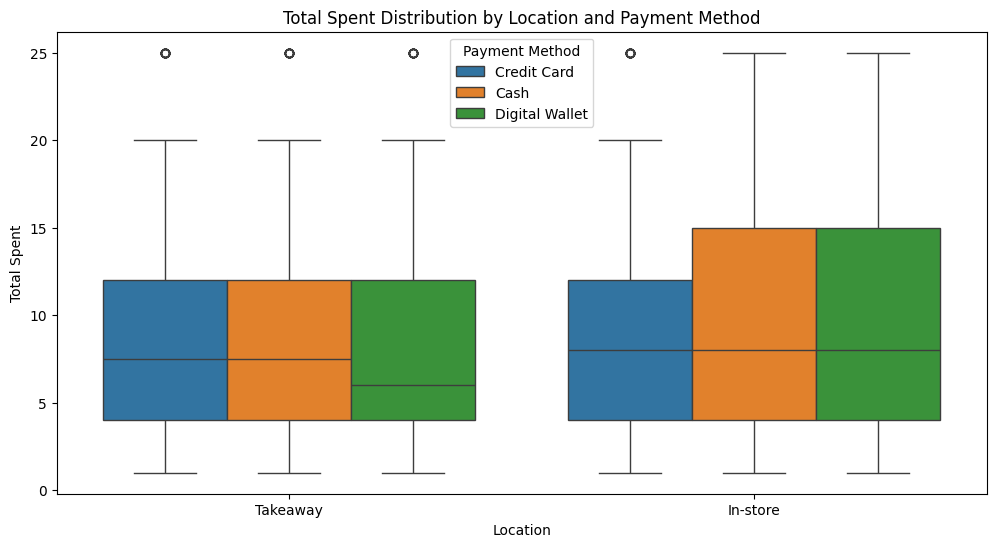

In [89]:
import seaborn as sns
import matplotlib.pyplot as plt


pivot_table = df.pivot_table(
    index='Location',
    columns='Payment Method',
    values='Total Spent',
    aggfunc='mean' 
)
print(pivot_table)

plt.figure(figsize=(12,6))
sns.boxplot(
    data=df,
    x='Location',
    y='Total Spent',
    hue='Payment Method'
)
plt.title('Total Spent Distribution by Location and Payment Method')
plt.show()


The box plots show that the data is tightly clustered, with no extreme outliers visible at this stage. We will proceed with cleaning and can re-evaluate if necessary.

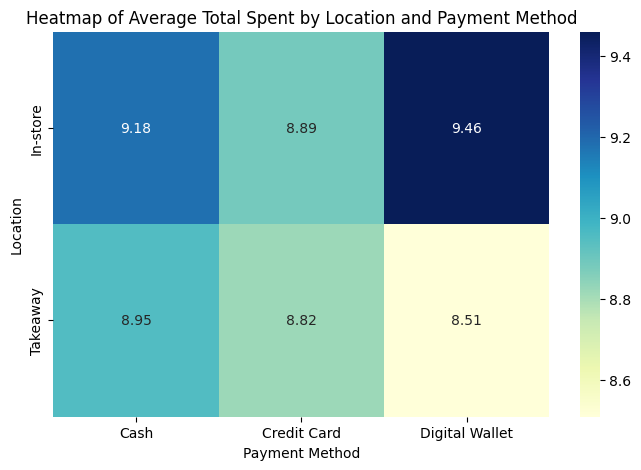

In [90]:
import seaborn as sns
import matplotlib.pyplot as plt

# إنشاء pivot table للمتوسطات
pivot_table = df.pivot_table(
    index='Location',
    columns='Payment Method',
    values='Total Spent',
    aggfunc='mean'
)

# رسم heatmap
plt.figure(figsize=(8,5))
sns.heatmap(pivot_table, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Heatmap of Average Total Spent by Location and Payment Method")
plt.ylabel("Location")
plt.xlabel("Payment Method")
plt.show()


In [91]:
# Fill missing Payment Method based on the most common method in the same Location
df['Payment Method'] = df.groupby('Location')['Payment Method']\
                         .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Unknown'))

# Fill missing Location with mode (most frequent value)
df['Location'].fillna(df['Location'].mode()[0], inplace=True)

# Conditional filling first
df['Payment Method'] = df.groupby('Location')['Payment Method']\
                         .transform(lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan))

# Any remaining unknowns, leave as 'Unknown'
df['Payment Method'].fillna('Unknown', inplace=True)

# Check remaining missing values
print(df[['Location', 'Payment Method']].isnull().sum())


Location          0
Payment Method    0
dtype: int64


In [92]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9540 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    9540 non-null   object        
 1   Item              9540 non-null   object        
 2   Quantity          9540 non-null   float64       
 3   Price Per Unit    9540 non-null   float64       
 4   Total Spent       9540 non-null   float64       
 5   Payment Method    9540 non-null   object        
 6   Location          9540 non-null   object        
 7   Transaction Date  9540 non-null   datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 670.8+ KB


### 7. Save Cleaned Dataset

In [93]:
# Save the cleaned dataframe to CSV
output_path = 'cafe_sales_cleaned.csv'
df.to_csv(output_path, index=False)
print(f"Saved cleaned dataframe to {output_path} (rows: {len(df)}, columns: {len(df.columns)})")

Saved cleaned dataframe to cafe_sales_cleaned.csv (rows: 9540, columns: 8)


# Before/after examples

In [94]:

raw_df = pd.read_csv('dirty_cafe_sales.csv')
display(raw_df.sample(n=5, random_state=42))

df.sample(n=5, random_state=42)



,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
6252,TXN_2919952,Juice,NaN,3.0,15.0,Digital Wallet,In-store,2023-02-17
4684,TXN_4265056,Juice,1,3.0,3.0,Cash,NaN,2023-07-16
1731,TXN_2463115,Sandwich,5,4.0,20.0,Credit Card,Takeaway,2023-09-12
4742,TXN_7619641,Juice,3,3.0,9.0,NaN,In-store,2023-04-02
4521,TXN_9566593,Cake,2,3.0,6.0,Digital Wallet,NaN,2023-09-30


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
4015,TXN_8413949,Juice,1.0,3.0,3.0,Credit Card,In-store,2023-10-14
4417,TXN_4447856,Smoothie,2.0,4.0,8.0,Cash,Takeaway,2023-09-11
8667,TXN_6763296,Coffee,5.0,2.0,10.0,Digital Wallet,Takeaway,2023-10-04
1670,TXN_2023802,Cake,2.0,3.0,6.0,Cash,In-store,2023-02-28
6641,TXN_5999810,Smoothie,4.0,4.0,16.0,Credit Card,Takeaway,2023-06-19


## Conclusion

The data has been successfully cleaned and preprocessed. The resulting `cafe_sales_cleaned.csv` file is now ready for exploratory data analysis, visualization, and building machine learning models. Key cleaning steps included handling missing values, removing duplicates, correcting data types, and standardizing text fields.